# Detecção de Evasão no Ensino Superior — Rede Neural (MLP)

Este notebook repete a análise de `projeto_evasao_escolar.ipynb`, mas usando uma **rede neural** (`MLPClassifier` do scikit-learn). Os mesmos testes são aplicados: três cenários de previsão (**matrícula**, **após o 1º semestre** e **após o 2º semestre**), mesmo split 70/30 estratificado, mesmas métricas (precision, recall e F1 da evasão) e matrizes de confusão.

A classe `Enrolled` é removida. O alvo é binário: `1` para evasão e `0` para graduação.

## 0. Como funciona uma rede neural (leitura rápida)

Uma rede neural é uma **linha de montagem de contas simples**:

1. **Neurônio:** recebe números (nota, idade, bolsa...), multiplica cada um por um **peso** (a importância dele), soma tudo e passa por uma **função de ativação**.
2. **Camadas:** neurônios são agrupados. A **entrada** tem um neurônio por variável; as **camadas ocultas** (aqui 64 e 32 neurônios) combinam as variáveis em padrões; a **saída** devolve a probabilidade de evasão (0 a 1). Acima de 0,5 o aluno é classificado como evasão.
3. **Ativação ReLU / sigmoide:** a ReLU zera valores negativos e deixa os positivos passarem (permite aprender relações não lineares); a sigmoide na saída espreme o resultado para 0–1.
4. **Aprendizado em ciclo:** a rede (a) faz um palpite, (b) mede o erro contra a resposta real, (c) usa *backpropagation* + otimizador **Adam** para corrigir levemente todos os pesos, e (d) repete. Uma passada completa pelo treino é uma **época**. A rede para quando deixa de melhorar (*early stopping*).

```
Variáveis → [64 neurônios] → [32 neurônios] → [1 neurônio] → probabilidade de evasão
```

> Documentação completa, com glossário: [`docs/rede_neural_mlp.md`](docs/rede_neural_mlp.md).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
DATA_PATH = Path("data") / "data.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH, sep=";")
df.columns = df.columns.str.replace("\t", " ", regex=False).str.strip()
names_pt = {
    "Marital status": "Estado civil",
    "Application mode": "Modalidade de ingresso",
    "Application order": "Ordem de ingresso",
    "Course": "Curso",
    "Daytime/evening attendance": "Turno (diurno/noturno)",
    "Previous qualification": "Qualificação anterior",
    "Previous qualification (grade)": "Nota da qualificação anterior",
    "Nacionality": "Nacionalidade",
    "Mother's qualification": "Qualificação da mãe",
    "Father's qualification": "Qualificação do pai",
    "Mother's occupation": "Ocupação da mãe",
    "Father's occupation": "Ocupação do pai",
    "Admission grade": "Nota de admissão",
    "Displaced": "Aluno deslocado",
    "Educational special needs": "Necessidades educacionais especiais",
    "Debtor": "Devedor",
    "Tuition fees up to date": "Mensalidades em dia",
    "Gender": "Gênero",
    "Scholarship holder": "Bolsista",
    "Age at enrollment": "Idade na matrícula",
    "International": "Estudante internacional",
    "Curricular units 1st sem (credited)": "Unidades curriculares 1º sem. (creditadas)",
    "Curricular units 1st sem (enrolled)": "Unidades curriculares 1º sem. (matriculadas)",
    "Curricular units 1st sem (evaluations)": "Unidades curriculares 1º sem. (avaliadas)",
    "Curricular units 1st sem (approved)": "Unidades curriculares 1º sem. (aprovadas)",
    "Curricular units 1st sem (grade)": "Nota média 1º semestre",
    "Curricular units 1st sem (without evaluations)": "Unidades curriculares 1º sem. (sem avaliação)",
    "Curricular units 2nd sem (credited)": "Unidades curriculares 2º sem. (creditadas)",
    "Curricular units 2nd sem (enrolled)": "Unidades curriculares 2º sem. (matriculadas)",
    "Curricular units 2nd sem (evaluations)": "Unidades curriculares 2º sem. (avaliadas)",
    "Curricular units 2nd sem (approved)": "Unidades curriculares 2º sem. (aprovadas)",
    "Curricular units 2nd sem (grade)": "Nota média 2º semestre",
    "Curricular units 2nd sem (without evaluations)": "Unidades curriculares 2º sem. (sem avaliação)",
    "Unemployment rate": "Taxa de desemprego",
    "Inflation rate": "Taxa de inflação",
    "GDP": "PIB",
    "Alvo": "Evasão"
}
print(f"Dimensões originais: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Colunas normalizadas: {list(df.columns)}")

Dimensões originais: 4424 linhas x 37 colunas
Colunas normalizadas: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', '

### Passo a passo: preparação (próxima célula)

1. Remove estudantes `Enrolled` (ainda cursando, sem resultado definitivo).
2. Converte o alvo: `Dropout → 1` (evasão) e `Graduate → 0`.
3. Cria **três cenários** conforme a informação disponível: *matrícula* (24 variáveis), *1º semestre* (30) e *2º semestre* (36).

In [2]:
if "Target" not in df.columns:
    raise KeyError("A coluna obrigatória 'Target' não foi encontrada.")

df = df.loc[df["Target"].isin(["Dropout", "Graduate"])].copy()
df["Alvo"] = df["Target"].map({"Dropout": 1, "Graduate": 0}).astype("int8")
df = df.drop(columns="Target")

features_enrollment = [
    col for col in df.columns
    if col not in ["Alvo"] and "1st sem" not in col.lower() and "2nd sem" not in col.lower()
]
features_sem1 = [
    col for col in df.columns
    if col != "Alvo" and "2nd sem" not in col.lower()
]
features_sem2 = [col for col in df.columns if col != "Alvo"]

scenarios = {
    "Matrícula": features_enrollment,
    "1º semestre": features_sem1,
    "2º semestre": features_sem2,
}

print(f"Registros definitivos: {len(df)}")
print(f"Evasão: {df['Alvo'].sum()} | Não evasão: {(df['Alvo'] == 0).sum()}")
for name, features in scenarios.items():
    print(f"{name}: {len(features)} variáveis")
    ,,,,,,,,,,,,,,,,]















    

Registros definitivos: 3630
Evasão: 1421 | Não evasão: 2209
Matrícula: 24 variáveis
1º semestre: 30 variáveis
2º semestre: 36 variáveis


## 1. Visão geral da base

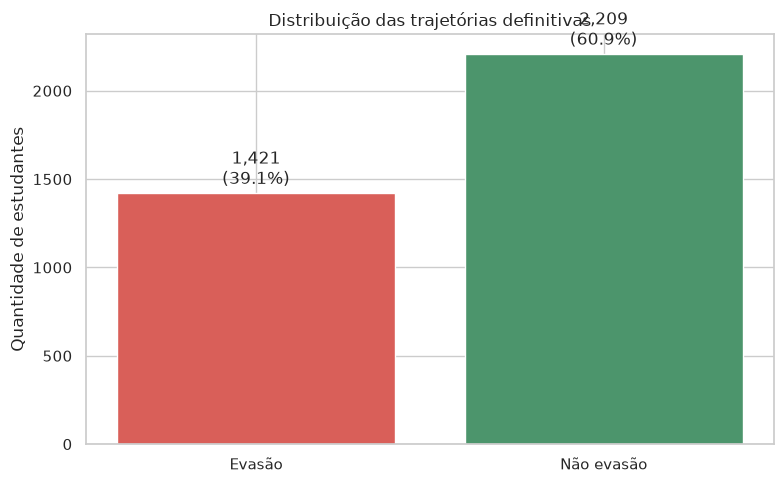

,Quantidade,Percentual (%)
Alvo,,
Evasão,1421,39.15
Não evasão,2209,60.85


In [3]:
counts = df["Alvo"].map({0: "Não evasão", 1: "Evasão"}).value_counts().reindex(["Evasão", "Não evasão"])
share = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(counts.index, counts.values, color=["#d95f59", "#4c956c"])
ax.set_title("Distribuição das trajetórias definitivas")
ax.set_ylabel("Quantidade de estudantes")
ax.set_xlabel("")
for bar, qtd, pct in zip(bars, counts, share):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
            f"{qtd:,}\n({pct:.1f}%)", ha="center", va="bottom")
plt.tight_layout()
plt.show()

pd.DataFrame({"Quantidade": counts, "Percentual (%)": share.round(2)})

## 2. Correlações no cenário do 1º semestre

Análise exploratória idêntica à do notebook original. Correlação não prova causalidade.

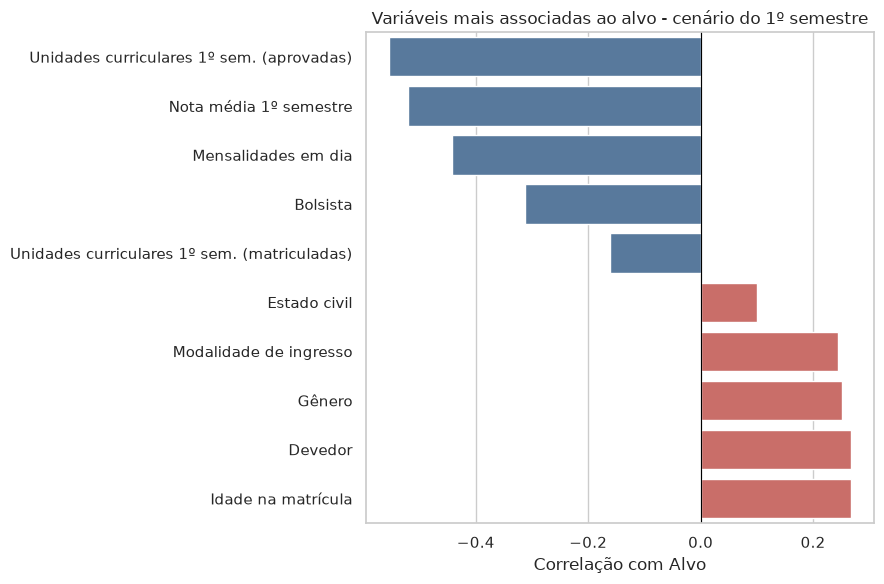

Notas e aprovações são o maior sinal de risco: menos aprovação, mais evasão. 
Mensalidade em dia e bolsa protegem o aluno: quem tem os dois evade menos. 
Perfil do aluno (idade, gênero, estado civil) tem efeito fraco.


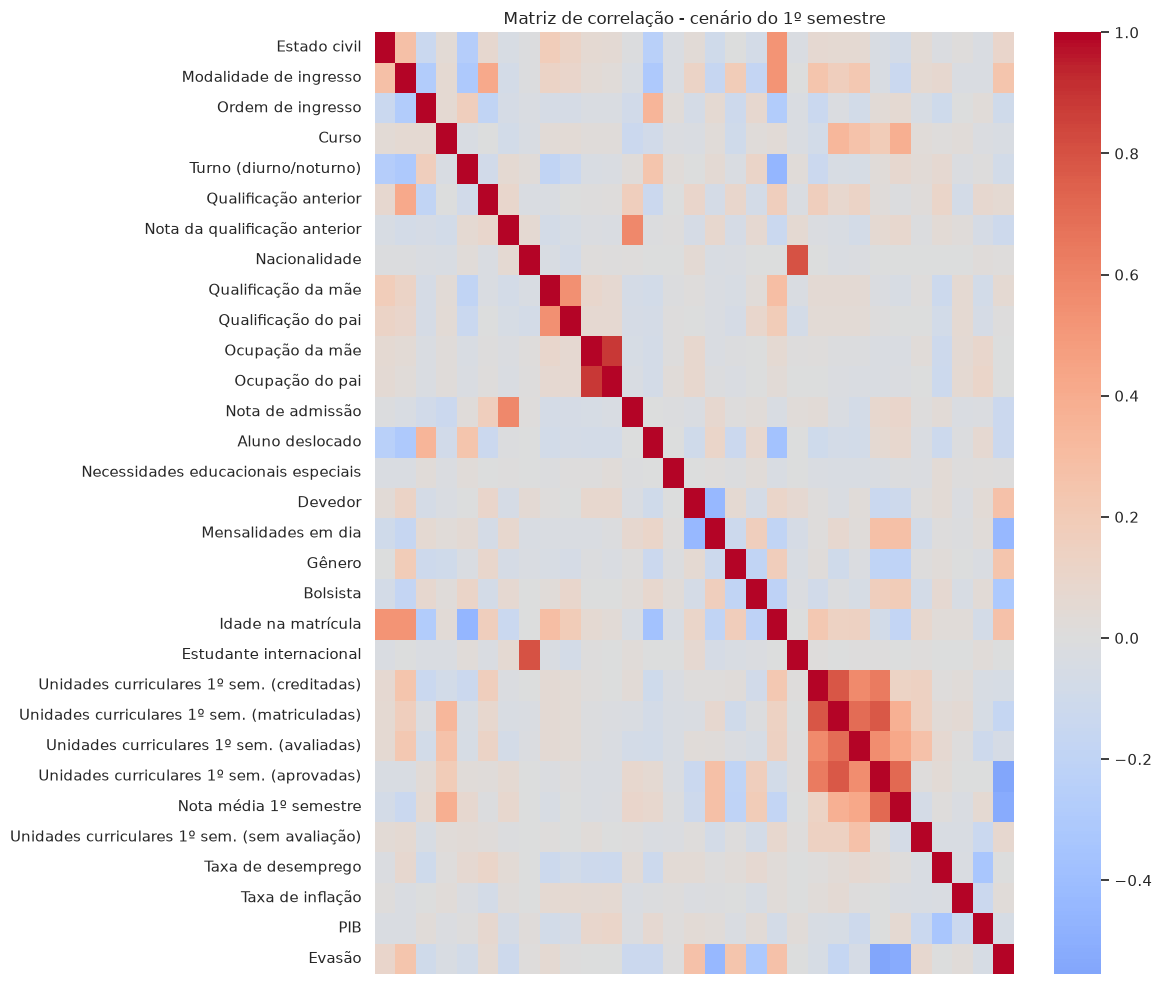

In [4]:
corr_target = df[features_sem1 + ["Alvo"]].corr(numeric_only=True)["Alvo"].drop("Alvo").sort_values()
top_corr_target = pd.concat([corr_target.head(5), corr_target.tail(5)]).sort_values()
top_corr_target.index = top_corr_target.index.map(names_pt)

plt.figure(figsize=(9, 6))
sns.barplot(x=top_corr_target.values, y=top_corr_target.index,
            hue=top_corr_target.values > 0, legend=False,
            palette={True: "#d95f59", False: "#4c78a8"})
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Variáveis mais associadas ao alvo - cenário do 1º semestre")
plt.xlabel("Correlação com Alvo")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(f"Notas e aprovações são o maior sinal de risco: menos aprovação, mais evasão. \nMensalidade em dia e bolsa protegem o aluno: quem tem os dois evade menos. \nPerfil do aluno (idade, gênero, estado civil) tem efeito fraco.")

plt.figure(figsize=(12, 10))
corr_matrix = df[features_sem1 + ["Alvo"]].corr(numeric_only=True)
corr_matrix.index = corr_matrix.index.map(names_pt)
sns.heatmap(corr_matrix,
            cmap="coolwarm", center=0, xticklabels=False, yticklabels=True)
plt.title("Matriz de correlação - cenário do 1º semestre")
plt.tight_layout()
plt.show()

## 3. Treinamento e avaliação

Esta é a etapa central. Passo a passo do que a célula seguinte faz, **para cada um dos três cenários**:

1. **Seleciona as variáveis** do cenário e converte para número.
2. **Separa treino (70%) e teste (30%)** com `stratify=y` (mesma proporção de evasão nos dois) e `random_state=42` (resultado reproduzível, idêntico ao notebook original). A rede aprende no treino e é avaliada em alunos que nunca viu.
3. **Padroniza as escalas** com `StandardScaler`: idade (~20), nota (~130) e inflação (~1) têm tamanhos muito diferentes, e redes neurais são sensíveis a isso. O scaler é ajustado (`fit`) **só no treino** e apenas aplicado (`transform`) no teste, para não vazar informação do teste (*data leakage*).
4. **Equilibra as classes no treino** (`oversample_minority`): o `MLPClassifier` não possui `class_weight`, então os casos de evasão são duplicados aleatoriamente até igualar as classes. O **teste não é alterado**. Sem isso a rede tenderia a chutar "não evasão" (≈ 61% dos casos).
5. **Cria uma rede nova** (`build_mlp`) e **treina** (`fit`).
6. **Prevê** o conjunto de teste (`predict`) e **calcula** precision, recall e F1 da evasão, além da matriz de confusão.

### Parâmetros da rede (`build_mlp`)

| Parâmetro | Valor | Significado simples |
|---|---|---|
| `hidden_layer_sizes` | `(64, 32)` | Duas camadas ocultas, com 64 e 32 neurônios |
| `activation` | `"relu"` | Ativação das camadas ocultas |
| `alpha` | `1e-3` | Regularização L2: penaliza pesos grandes e evita decorar o treino (*overfitting*) |
| `early_stopping` | `True` | Reserva parte do treino para validação e para quando a rede não melhora mais |
| `validation_fraction` | `0.1` | 10% do treino usado nessa validação interna |
| `n_iter_no_change` | `10` | Para após 10 épocas sem melhora |
| `max_iter` | `500` | Limite de épocas, por segurança |
| `random_state` | `42` | Pesos iniciais reproduzíveis |

### O que significa cada score

- **Precision:** dos alunos sinalizados como risco, quantos realmente evadiram (qualidade dos alertas).
- **Recall:** dos alunos que realmente evadiram, quantos a rede encontrou (cobertura). **É a métrica prioritária**: falso negativo é um aluno em risco sem acompanhamento.
- **F1:** equilíbrio entre precision e recall.

## Por que cada escolha? (decisões de projeto)

> **Aviso honesto:** os hiperparâmetros da rede (tamanho das camadas, `alpha`, etc.) são **pontos de partida razoáveis**, não valores otimizados por busca. Eles seguem práticas comuns e foram justificados pelo tamanho da base. Uma busca sistemática (`GridSearchCV`) pode melhorar o resultado.

### Escolha do modelo

| Decisão | Por que | Alternativa descartada |
|---|---|---|
| **Rede neural (MLP)** | Foi o que se pediu para testar. Captura combinações não lineares entre variáveis (ex.: nota baixa **e** mensalidade atrasada) sem precisarmos desenhá-las à mão. | — |
| **`MLPClassifier` do scikit-learn** | A base é **tabular e pequena** (3.630 linhas): não justifica Keras/PyTorch nem GPU. Usa a mesma API (`fit`/`predict`) dos modelos do notebook original, o que permite comparar de forma direta e justa. | Keras/PyTorch: mais flexíveis, porém mais código e dependências para ganho improvável aqui. |
| **Mesmo split, cenários e métricas do original** | Só muda o modelo. Assim qualquer diferença nos números vem da rede, não de um teste diferente. | — |

### Escolha dos parâmetros da rede

| Parâmetro | Valor | Por que esse valor |
|---|---|---|
| `hidden_layer_sizes` | `(64, 32)` | Formato de **funil** (afunila da entrada até a saída): a 1ª camada combina as ~30 variáveis em muitos padrões e a 2ª os resume. Duas camadas bastam para dados tabulares; mais profundidade tende a só aumentar o risco de decorar. Com ~4 mil pesos e ~2,5 mil estudantes no treino, a rede **já é grande para a base**, por isso não aumentamos mais. |
| `activation` | `relu` | Padrão consagrado: barata de calcular e evita que o aprendizado "morra" em redes com mais de uma camada (problema do gradiente que some, comum em `tanh`/`logistic`). |
| Otimizador | `adam` (padrão) | Ajusta sozinho o tamanho do passo de cada peso, funcionando bem **sem** ajustar taxa de aprendizado. `lbfgs` seria uma opção para bases muito pequenas, mas é menos estável nessa escala e não permite `early_stopping`. |
| `alpha` | `1e-3` | Como há mais pesos do que estudantes, o risco de *overfitting* é alto. O padrão do scikit-learn é `1e-4`; usamos 10× mais para **frear pesos grandes**. Valores bem maiores (≥ 1e-1) deixariam a rede simples demais e derrubariam o recall. |
| `early_stopping=True` | ligado | Principal defesa contra decorar o treino: monitora um conjunto de validação e **interrompe quando a rede para de melhorar**. É também por isso que não precisamos escolher o nº de épocas à mão (a rede parou em 20 a 63). |
| `validation_fraction` | `0.1` | 10% é o padrão: separa dados suficientes para a validação ser confiável sem tirar demais do treino. |
| `n_iter_no_change` | `10` | "Paciência": a curva de erro oscila; esperar 10 épocas evita parar por causa de um ruído passageiro. |
| `max_iter` | `500` | Apenas teto de segurança. Nunca foi atingido, pois o *early stopping* encerra bem antes. |
| `random_state` | `42` | Reprodutibilidade (pesos iniciais e sorteios iguais a cada execução) e o mesmo valor do notebook original. |

### Escolha do pré-processamento e da avaliação

| Decisão | Por que | Alternativa descartada |
|---|---|---|
| **`StandardScaler`** | Redes aprendem por gradiente, e variáveis em escalas muito diferentes (idade ~20 vs. nota ~130) fazem as de número grande dominarem. Árvores não precisam disso; a rede **precisa**. | Treinar sem escalar: convergência lenta e resultado pior. |
| **`fit` do scaler só no treino** | Evita *data leakage*: o teste deve simular dados que ainda não existem. | Ajustar na base toda: infla as métricas artificialmente. |
| **Sobreamostragem só no treino** | O `MLPClassifier` não tem `class_weight`. Duplicar a classe rara é a forma mais simples de equilibrar e **não exige biblioteca extra**. Só no treino, porque o teste precisa refletir a proporção real (≈ 39% de evasão). | *Undersampling*: descartaria ~35% dos dados numa base já pequena. *SMOTE*: cria exemplos sintéticos, mas exige `imbalanced-learn` (não instalado) e adiciona complexidade para o MVP. |
| **Split 70/30 estratificado** | O teste de 30% (1.089 alunos) é grande o bastante para métricas estáveis. A estratificação mantém a proporção de evasão nos dois lados. É o mesmo split do notebook original. | Validação cruzada: mais robusta, mas muda a comparação com o original (listada como melhoria futura). |
| **Limiar de decisão 0,5 (padrão)** | Mantém a comparação equivalente aos outros modelos. | Reduzir o limiar (ex.: 0,4) **aumentaria o recall** à custa de mais alertas falsos; é uma alavanca futura se a coordenação preferir cobrir mais casos. |
| **Recall como métrica prioritária** | Falso negativo = aluno em risco sem acompanhamento (custo alto). Falso positivo = uma conversa desnecessária (custo baixo). | Acurácia: enganosa com classes desbalanceadas. |
| **Três cenários** | Respondem "**quando** dá para prever?": na matrícula há mais tempo para agir, mas menos precisão; após o 2º semestre há mais precisão, mas menos tempo. | — |

### Escolha da explicabilidade

| Decisão | Por que | Alternativa descartada |
|---|---|---|
| **Importância por permutação** | Funciona com **qualquer** modelo (a MLP não tem `feature_importances_`) e já vem no scikit-learn. É fácil de explicar: "embaralhei a variável e o recall caiu X". | SHAP: mais detalhado (explica cada aluno), porém mais pesado e com dependência extra; fica como evolução. |
| **`scoring="recall"`** | Mede a importância **na métrica que mais interessa** ao projeto. | Usar acurácia: poderia destacar variáveis irrelevantes para encontrar evadidos. |
| **Calculada no conjunto de teste** | Mostra o que a rede usa para **generalizar**, não o que ela decorou no treino. | Calcular no treino: favorece variáveis que só ajudam a decorar. |
| **Cenário do 1º semestre** | É o melhor equilíbrio entre antecedência e desempenho, e o mesmo usado no original. | — |


In [5]:
def build_mlp():
    return MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        alpha=1e-3,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        max_iter=500,
        random_state=RANDOM_STATE,
    )


def oversample_minority(X, y):
    """Duplicate minority-class rows (train only) until classes are balanced."""
    minority = y.value_counts().idxmin()
    X_min, y_min = X[y == minority], y[y == minority]
    X_maj, y_maj = X[y != minority], y[y != minority]
    X_up, y_up = resample(X_min, y_min, replace=True, n_samples=len(y_maj), random_state=RANDOM_STATE)
    return np.vstack([X_maj, X_up]), np.concatenate([y_maj, y_up])


results = []
artifacts = {}
y = df["Alvo"]

for scenario_name, features in scenarios.items():
    X = df[features].apply(pd.to_numeric, errors="raise")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
    )
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    X_train_bal, y_train_bal = oversample_minority(X_train_scaled, y_train.reset_index(drop=True))

    model = build_mlp()
    model.fit(X_train_bal, y_train_bal)
    preds = model.predict(X_test_scaled)
    results.append({
        "Cenário": scenario_name,
        "Modelo": "Rede Neural (MLP)",
        "Precision (evasão)": precision_score(y_test, preds, zero_division=0),
        "Recall (evasão)": recall_score(y_test, preds, zero_division=0),
        "F1 (evasão)": f1_score(y_test, preds, zero_division=0),
    })
    artifacts[scenario_name] = {
        "model": model, "features": features, "X_test": X_test_scaled, "y_test": y_test,
        "preds": preds, "matrix": confusion_matrix(y_test, preds), "n_iter": model.n_iter_,
    }

results_df = pd.DataFrame(results).sort_values("Recall (evasão)", ascending=False)
results_df.style.format({"Precision (evasão)": "{:.3f}", "Recall (evasão)": "{:.3f}", "F1 (evasão)": "{:.3f}"})

,Cenário,Modelo,Precision (evasão),Recall (evasão),F1 (evasão)
2,2º semestre,Rede Neural (MLP),0.914,0.871,0.892
1,1º semestre,Rede Neural (MLP),0.857,0.819,0.838
0,Matrícula,Rede Neural (MLP),0.690,0.700,0.695


### Comentário sobre o treinamento

- **O que foi feito:** uma MLP foi treinada e avaliada nos três cenários, com o mesmo split e métricas do notebook original.
- **Por que isso foi feito:** permite comparar diretamente a rede neural com Regressão Logística, Árvore e Random Forest.
- **Conclusão:** veja a tabela acima. Em dados tabulares pequenos, redes neurais costumam empatar com modelos de árvore, não superá-los.

### Como ler a próxima célula

- **`classification_report`:** precision, recall e F1 de cada classe. Olhe a linha **Evasão**.
- **Iterações até parar:** quantas épocas a rede treinou antes do *early stopping*.
- **Matriz de confusão** (linhas = real, colunas = previsto): a diagonal são os acertos. O canto inferior esquerdo (real *evasão*, previsto *não evasão*) são os **falsos negativos**, o erro mais caro neste projeto; o canto superior direito são alertas desnecessários (falsos positivos).

=== Matrícula (iterações até parar: 20) ===
              precision    recall  f1-score   support

  Não evasão      0.805     0.798     0.802       663
      Evasão      0.690     0.700     0.695       426

    accuracy                          0.759      1089
   macro avg      0.747     0.749     0.748      1089
weighted avg      0.760     0.759     0.760      1089

=== 1º semestre (iterações até parar: 43) ===
              precision    recall  f1-score   support

  Não evasão      0.887     0.913     0.900       663
      Evasão      0.857     0.819     0.838       426

    accuracy                          0.876      1089
   macro avg      0.872     0.866     0.869      1089
weighted avg      0.876     0.876     0.875      1089

=== 2º semestre (iterações até parar: 63) ===
              precision    recall  f1-score   support

  Não evasão      0.919     0.947     0.933       663
      Evasão      0.914     0.871     0.892       426

    accuracy                          0.917   

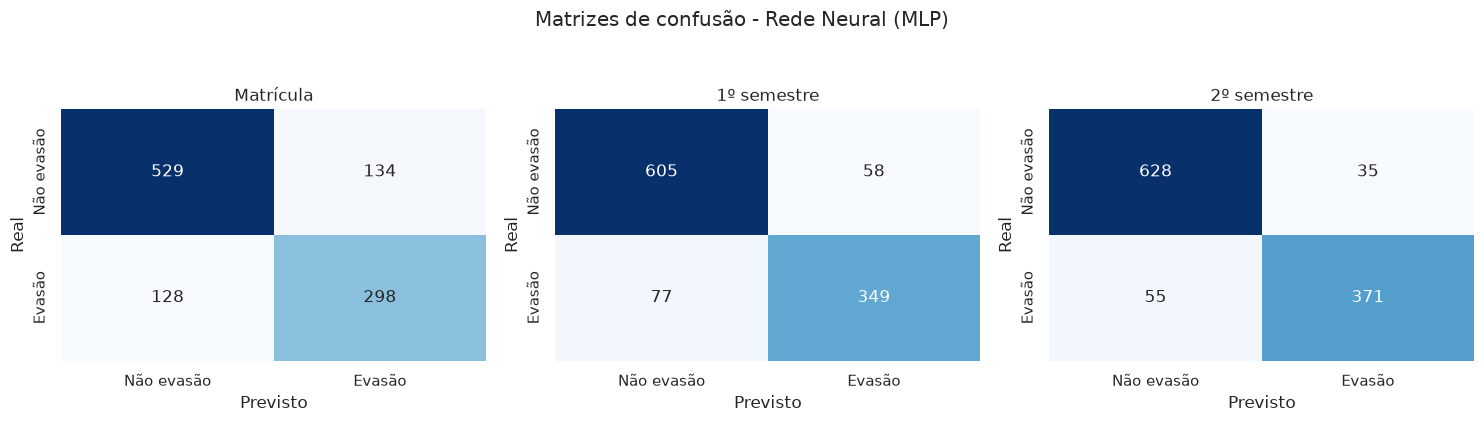

In [6]:
for scenario_name in scenarios:
    print(f"=== {scenario_name} (iterações até parar: {artifacts[scenario_name]['n_iter']}) ===")
    a = artifacts[scenario_name]
    print(classification_report(a["y_test"], a["preds"], target_names=["Não evasão", "Evasão"], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, scenario_name in zip(axes, scenarios):
    sns.heatmap(artifacts[scenario_name]["matrix"], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Não evasão", "Evasão"], yticklabels=["Não evasão", "Evasão"])
    ax.set_title(scenario_name)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
fig.suptitle("Matrizes de confusão - Rede Neural (MLP)", y=1.05)
plt.tight_layout()
plt.show()

### Comentário sobre a MLP

- **O que foi feito:** relatório de classificação e matrizes de confusão por cenário.
- **Por que isso foi feito:** o recall mede quantos estudantes em risco foram encontrados; a matriz mostra falsos positivos e falsos negativos.
- **Conclusão:** falsos negativos continuam sendo estudantes em risco não sinalizados e merecem atenção.

## 4. Explicabilidade e conclusão

Redes neurais são "caixas-pretas": olhar os pesos não diz quais variáveis importam e o modelo não possui `feature_importances_`. Por isso usa-se a **importância por permutação**, no cenário do 1º semestre:

1. Mede o recall do modelo no conjunto de teste.
2. **Embaralha uma única variável**, quebrando a relação dela com a evasão, e mede o recall de novo.
3. **Quanto mais o recall cai, mais a rede dependia daquela variável.**
4. Repete 10 vezes por variável (`n_repeats=10`) e usa a média. O gráfico mostra as 10 maiores quedas.

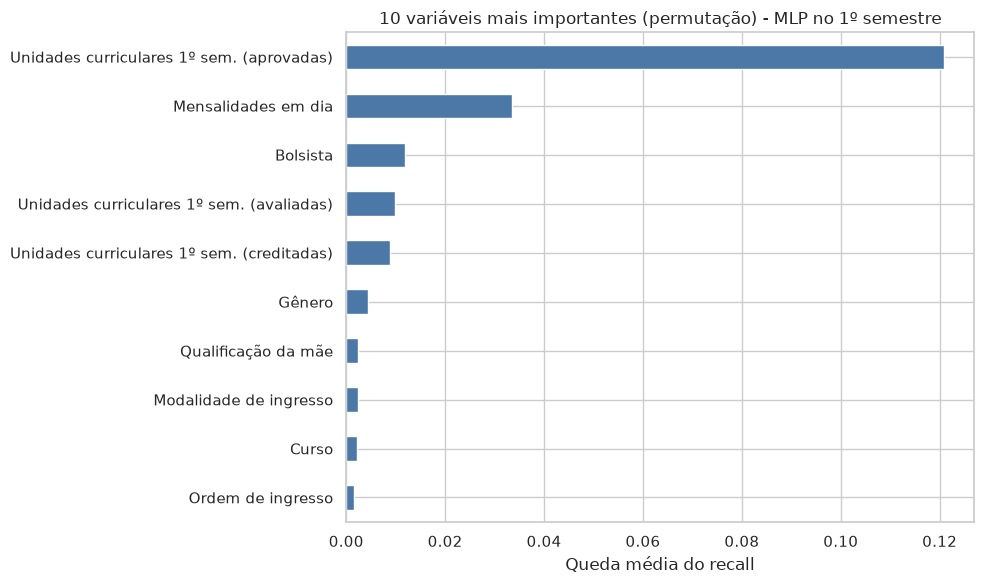

Melhor recall de evasão da MLP: 2º semestre (0.871)

Interpretação: o recall deve ser priorizado porque falsos negativos representam estudantes em risco que não receberiam atenção.


In [7]:
a = artifacts["1º semestre"]
perm = permutation_importance(
    a["model"], a["X_test"], a["y_test"], scoring="recall",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)
importances = pd.Series(perm.importances_mean, index=a["features"])
importances = importances.sort_values(ascending=False).head(10).sort_values()
importances.index = importances.index.map(names_pt)

plt.figure(figsize=(10, 6))
importances.plot(kind="barh", color="#4c78a8")
plt.title("10 variáveis mais importantes (permutação) - MLP no 1º semestre")
plt.xlabel("Queda média do recall")
plt.ylabel("")
plt.tight_layout()
plt.show()

best = results_df.set_index("Cenário")["Recall (evasão)"].idxmax()
print(f"Melhor recall de evasão da MLP: {best} ({results_df.set_index('Cenário').loc[best, 'Recall (evasão)']:.3f})")
print("\nInterpretação: o recall deve ser priorizado porque falsos negativos representam estudantes em risco que não receberiam atenção.")

### Comentário sobre a explicabilidade e a conclusão

- **O que foi feito:** importância por permutação das variáveis no cenário do 1º semestre.
- **Por que isso foi feito:** entender quais variáveis a rede usa ajuda a coordenação a priorizar ações.
- **Conclusão:** as variáveis indicam onde investigar, não a causa da evasão. O modelo apoia, não substitui, a avaliação humana.